# CS3CI Lab Notebook
This covers week 1 to week 6 labs, I will set time-based terminations to end after 10 seconds and other termination conditions to finish in approximately 30 seconds.


## Lab 1

In [10]:
# -------------------------------------
# Step 1: Data Structure for the Graph
# -------------------------------------

adjacency_matrix = [
    [0, 20, 42, 35],
    [20, 0, 30, 34],
    [42, 30, 0, 12],
    [35, 34, 12, 0]
]

print("-"*50+"\n"+"Running Step 1: Data Structure for the Graph ...\n"+"-"*50+f"\n{adjacency_matrix}\n")
print("-"*50+"\n"+f"adjacency_matrix[0][1] = {adjacency_matrix[0][1]}"+"\n"+"-"*50)

--------------------------------------------------
Running Step 1: Data Structure for the Graph ...
--------------------------------------------------
[[0, 20, 42, 35], [20, 0, 30, 34], [42, 30, 0, 12], [35, 34, 12, 0]]

--------------------------------------------------
adjacency_matrix[0][1] = 20
--------------------------------------------------


In [11]:
# ---------------------------------------
# Step 2: Defining and Evaluating Routes
# ---------------------------------------

adjacency_matrix = [
    [0, 20, 42, 35],
    [20, 0, 30, 34],
    [42, 30, 0, 12],
    [35, 34, 12, 0]
]

def evaluate_tsp(adjacency_matrix, route):
    total_cost = 0
    num_cities = len(route)

    for i in range(num_cities):
        from_city = route[i]
        to_city = route[(i + 1) % num_cities]  # '% num_cities' makes route circular 
        total_cost += adjacency_matrix[from_city][to_city]

    return total_cost

print("-"*50+"\n"+"Running Step 2: Defining and Evaluating Routes ...\n"+"-"*50+"\n")

route = [0, 1, 2, 3]
cost = evaluate_tsp(adjacency_matrix, route)
print(f"Route: {route}")
print(f"Total cost: {cost}")

--------------------------------------------------
Running Step 2: Defining and Evaluating Routes ...
--------------------------------------------------

Route: [0, 1, 2, 3]
Total cost: 97


In [12]:
# -------------------------------
# Step 3: Generate Random Routes
# -------------------------------

import random

def calc_routes(n):
    print("Calculating the number of possible 2-way routes where each city connects to every other city ...")
    return n * (n - 1) // 2

def random_tsp(num_cities, min_cost=1, max_cost=100):
    adjacency_matrix = [
        [0 for _ in range(num_cities)]
        for _ in range(num_cities)
    ]

    print("Generating Routes ...")
    for i in range(num_cities):
        for j in range(i + 1, num_cities):
            cost = random.randint(min_cost, max_cost)
            adjacency_matrix[i][j] = cost
            adjacency_matrix[j][i] = cost

    return adjacency_matrix

def random_route(num_city):

    route = list(range(1, num_city))
    random.shuffle(route)

    return [0] + route

    """
    Evaluate the cost of a given TSP route based on the adjacency matrix.
    """
    total_cost = 0
    num_cities = len(route)

    for i in range(num_cities):
        from_city = route[i]
        to_city = route[(i + 1) % num_cities]  # '% num_cities' makes route circular 
        total_cost += adjacency_matrix[from_city][to_city]

    return total_cost

def get_routes(adjacency_matrix):
    routes = []

    for i in range(len(adjacency_matrix)):
        for j in range(i + 1, len(adjacency_matrix)):
            cost = adjacency_matrix[i][j]
            routes.append((i, j, cost))

    return routes

print("-"*50+"\n"+"Running Step 3: Generate Random Routes ...\n"+"-"*50+"\n")

num_city = int(input("Enter the number of cities: "))

num_routes = calc_routes(num_city)
print(f"The number of possible 2-way routes for {num_city} cities is: {num_routes}")

adjacency_matrix = random_tsp(num_city)
print(f"Size of adjacency matrix: {len(adjacency_matrix)} x {len(adjacency_matrix[0])}")

print("Adjacency Matrix: ")
for row in adjacency_matrix:
    print(row)

routes = get_routes(adjacency_matrix)
# print("All unique routes between cities:")
# for from_city, to_city, cost in routes:
#     print(f"Route from City {from_city} to City {to_city}: Cost = {cost}")
print(routes)

route = random_route(num_city)
print(f"Random TSP Route: {route}")

cost = evaluate_tsp(adjacency_matrix, route)
print(f"Total cost of the route: {cost}")


--------------------------------------------------
Running Step 3: Generate Random Routes ...
--------------------------------------------------

Calculating the number of possible 2-way routes where each city connects to every other city ...
The number of possible 2-way routes for 5 cities is: 10
Generating Routes ...
Size of adjacency matrix: 5 x 5
Adjacency Matrix: 
[0, 23, 20, 55, 58]
[23, 0, 50, 11, 76]
[20, 50, 0, 36, 52]
[55, 11, 36, 0, 92]
[58, 76, 52, 92, 0]
[(0, 1, 23), (0, 2, 20), (0, 3, 55), (0, 4, 58), (1, 2, 50), (1, 3, 11), (1, 4, 76), (2, 3, 36), (2, 4, 52), (3, 4, 92)]
Random TSP Route: [0, 3, 4, 1, 2]
Total cost of the route: 293


In [13]:
# -----------------------------------------------------------------
# Step 4: Try a Bigger Problem Instance
# -----------------------------------------------------------------

import pandas as pd
import numpy as np

def build_adj_matrix_float(num_cities):
    adj_matrix = [
        [0.0 for _ in range(num_cities)]
        for _ in range(num_cities)
    ]
    return adj_matrix

# evaluate_tsp() in Step 2
# random_route() and get_routes() are already defined in Step 3
# Run above cells for missing method def's

print("-"*50+"\n"+"Running Step 4: Try a Bigger Problem Instance ...\n"+"-"*50+"\n")

df = pd.read_csv('ulysses16.csv')

print(f"City Locations (according to ulysses16.csv): \n{df}\n")
print(f"Shape of the DataFrame: {df.shape}")

num_cities = len(df)

adj_matrix = build_adj_matrix_float(num_cities)

for i in range(num_cities):
    for j in range(i + 1, num_cities):
        x_i = df.iloc[i]["x"]
        y_i = df.iloc[i]["y"]

        x_j = df.iloc[j]["x"]
        y_j = df.iloc[j]["y"]

        distance = float(
            np.sqrt((x_i - x_j) ** 2 + (y_i - y_j) ** 2)
        )

        adj_matrix[i][j] = distance
        adj_matrix[j][i] = distance

print("Adjacency Matrix: ")
for row in adj_matrix:
    print([round(distance, 2) for distance in row])

routes = get_routes(adj_matrix)
print(f"\nNumber of unique connections: {len(routes)}")
print("All unique routes between cities:")

routes_df = pd.DataFrame(
    routes,
    columns=["From", "To", "Cost"]
)

routes_df["Cost"] = routes_df["Cost"].round(2)

columns = 4
chunk_size = (len(routes_df) + columns - 1) // columns

chunks = [
    routes_df.iloc[i:i + chunk_size]
    for i in range(0, len(routes_df), chunk_size)
]

tables = [
    chunk.to_string(index=False)
    for chunk in chunks
]

table_lines = [table.split("\n") for table in tables]

for lines in zip(*table_lines):
    print(" | ".join(lines))

route = random_route(num_cities)
print(f"Random Route: {route}")

cost = evaluate_tsp(adj_matrix, route)
print(f"Total cost: {cost:.2f}")

--------------------------------------------------
Running Step 4: Try a Bigger Problem Instance ...
--------------------------------------------------

City Locations (according to ulysses16.csv): 
        x      y
0   38.24  20.42
1   39.57  26.15
2   40.56  25.32
3   36.26  23.12
4   33.48  10.54
5   37.56  12.19
6   38.42  13.11
7   37.52  20.44
8   41.23   9.10
9   41.17  13.05
10  36.08  -5.21
11  38.47  15.13
12  38.15  15.35
13  37.51  15.17
14  35.49  14.32
15  39.36  19.56

Shape of the DataFrame: (16, 2)
Adjacency Matrix: 
[0.0, 5.88, 5.42, 3.35, 10.97, 8.26, 7.31, 0.72, 11.71, 7.93, 25.72, 5.29, 5.07, 5.3, 6.69, 1.41]
[5.88, 0.0, 1.29, 4.49, 16.76, 14.1, 13.09, 6.07, 17.13, 13.2, 31.55, 11.07, 10.89, 11.17, 12.51, 6.59]
[5.42, 1.29, 0.0, 4.83, 16.39, 13.47, 12.4, 5.75, 16.23, 12.29, 30.86, 10.4, 10.26, 10.6, 12.11, 5.88]
[3.35, 4.49, 4.83, 0.0, 12.88, 11.01, 10.24, 2.96, 14.87, 11.2, 28.33, 8.29, 8.0, 8.05, 8.83, 4.72]
[10.97, 16.76, 16.39, 12.88, 0.0, 4.4, 5.57, 10.69, 7.8

## Lab 2
Downloaded lab1code.zip from blackboard as basis of lab 2

In [14]:
#
# IMPORTANT: IMPORTS
#

import pandas as pd
import time
## from lib import tsp

### tsp.py from lab1code.zip

In [15]:
import numpy as np
import math
import matplotlib.pyplot as plt
import networkx as nx
from networkx.classes.function import path_weight
import random

# Constructs a TSP instance from a matrix (i.e. list of lists) adjacency_matrix
# in which adjacency_matrix[i][j] corresponds to the length of the edge from
# city i to city j.
def construct(adjacency_matrix):
  return nx.from_numpy_array(np.matrix(adjacency_matrix))

# Constructs a TSP instance from a matrix city_coords in which each row of the
# matrix represents the Cartesian coordinates of a city.
def construct_from_city_coords(city_coords):
  def dist(x,y):
    return math.sqrt((x[0] - y[0])**2 + (x[1] - y[1])**2)

  adjacency_matrix = [ [dist(x,y) for x in city_coords] for y in city_coords]
  
  return construct(adjacency_matrix)

# Displays a TSP instance on a 2D plane. Optional args:
#  - city_coords: Cartesian coordinates of the cities use to position cities in
#    the 2D plane. If no coordinates are provided, arbitrary ones are
#    generated.
#  - label_edges: Whether or not the edges of the graph should be labelled with
#    their weights. It is recommended to set this as False for all but very
#    small graphs as the number of edges quickly grows very large.
#  - title: A title for the plot
def display_instance(tsp_instance,city_coords = None,label_edges=False,title=None):
  if city_coords is None:
    city_coords = nx.spring_layout(tsp_instance)
  
  # First, we create a new figure into which to plot our graph.
  plt.figure()
  # With the positions defined, we can now draw the graph itself...
  nx.draw_networkx(tsp_instance,city_coords)
  # ... and, if we wish, we can label the edges according to their weights.
  if label_edges:
    edge_labels = nx.get_edge_attributes(tsp_instance,'weight')
    nx.draw_networkx_edge_labels(tsp_instance,city_coords,edge_labels=edge_labels)
  # Add a title to the plot
  if title is not None:
    plt.title(title)
  # Finally, we display the graph
  plt.show()

# Checks that an array specifies a valid TSP route. A valid TSP route should:
#   - visit all cities
#   - visit its starting city twice: once at the start and once at the end of
#     the route,
#   - aside from its starting city, it should visit each city exactly once. 
#
# An example of a valid route for a TSP instance with 4 cities would be 
# [1,2,3,0,1].
def is_valid_route(tsp_instance,route):
  number_of_cities = tsp_instance.number_of_nodes()
  # Check if the route returns to the starting city
  if route[0] != route[-1]: return False
  # Check that only the starting city is repeated in the route
  elif len(route) != len(set(route)) + 1: return False
  # Check all cities have been visited
  elif len(route) != number_of_cities + 1: return False
  # If so, the route is valid
  else: return True

# Displays a TSP instance on a 2D plane. Overlays a specified route on this
# instance. Optional args:
#  - city_coords: Cartesian coordinates of the cities use to position cities in
#    the 2D plane. If no coordinates are provided, arbitrary ones are
#    generated.
#  - label_edges: Whether or not the edges of the graph should be labelled with
#    their weights. It is recommended to set this as False for all but very
#    small graphs as the number of edges quickly grows very large.
#  - title: A title for the plot
def display_route(tsp_instance,route,city_coords = None,label_edges=False,title=None):
  if not is_valid_route(tsp_instance,route):
    raise ValueError('{} is not a valid route for a TSP instance with {} cities'.format(route,tsp_instance.number_of_nodes()))
  
  if city_coords is None:
    city_coords = nx.spring_layout(tsp_instance)

  # First, we create a new figure into which to plot our graph.
  plt.figure()
  # With the positions defined, we can now draw the TSP instance itself...
  nx.draw_networkx(tsp_instance,city_coords,edge_color="blue",width=0.5)

  # ...then overlay the route.
  edge_list = list(nx.utils.pairwise(route))
  nx.draw_networkx(
    tsp_instance,
    city_coords,
    edgelist=edge_list,
    edge_color="red",
    width=3,
  )
  # Label the edges according to their weights.
  if label_edges:
    edge_labels = nx.get_edge_attributes(tsp_instance,'weight')
    nx.draw_networkx_edge_labels(tsp_instance,city_coords,edge_labels=edge_labels)
  # Add a title to the plot
  if title is not None:
    plt.title(title)
  # Finally, we display the graph
  plt.show()

# Evaluates a given route on a TSP instance, returning the total length of the
# tour.
def evaluate(tsp_instance,route):
  if not is_valid_route(tsp_instance,route):
    raise ValueError('{} is not a valid route for a TSP instance with {} cities'.format(route,tsp_instance.number_of_nodes()))
  return path_weight(tsp_instance, route, weight="weight")

# Generates a random, valid route for a given TSP instance. As TSP routes are
# complete loops, we will generate routes which start and end at city 0.
def random_route(tsp_instance):
  number_of_cities = tsp_instance.number_of_nodes()
  # Start with a valid route (minus the starting city - city 0).
  route_middle = [*range(1,number_of_cities)]
  # Shuffle the route into a random order.
  random.shuffle(route_middle)
  # Add the starting city and loop back to it at the end.
  return [0] + route_middle + [0]

### Step 1: Random Initialisation

Take Random Route from either Lab 1 or by running "tsp from lab1code.zip" section
Following cell is copy paste of what was inside lab1code.zip's main.py

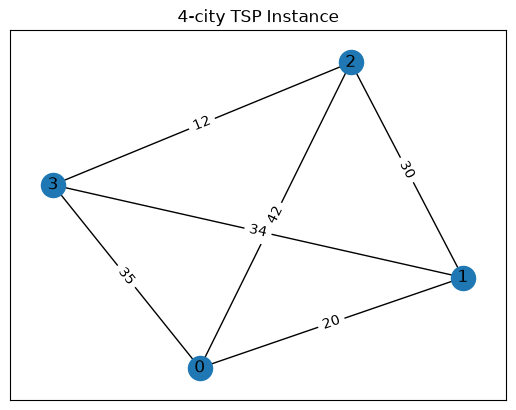

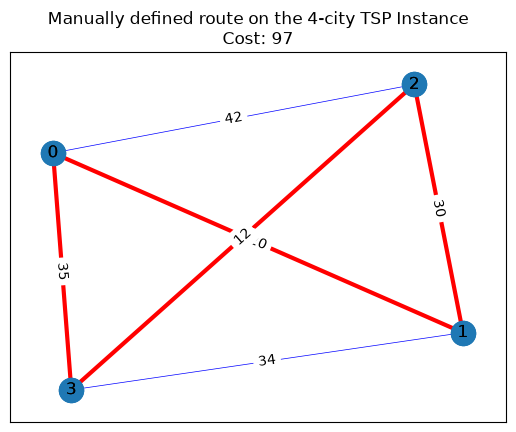

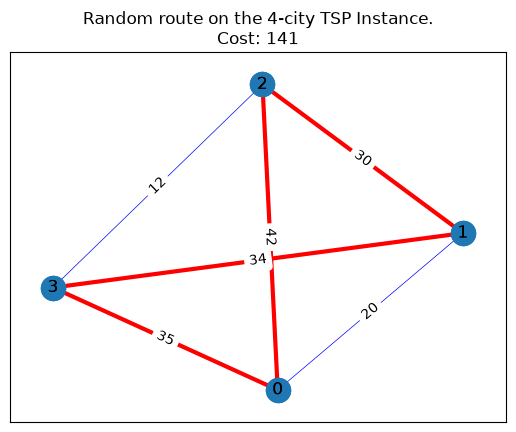

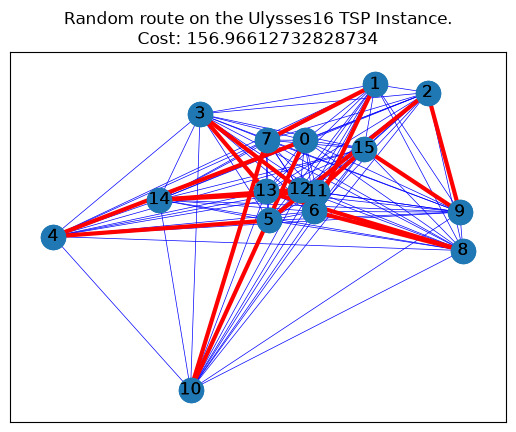

In [16]:
###############################################################################
# Step 1
###############################################################################

adjacency_matrix = [
  [0,20,42,35],
  [20,0,30,34],
  [42,30,0,12],
  [35,34,12,0]
]
small_tsp_instance = construct(adjacency_matrix)
display_instance(small_tsp_instance,label_edges=True,title="4-city TSP Instance")

###############################################################################
# Step 2
###############################################################################

test_route = [0,1,2,3,0]
test_route_cost = evaluate(small_tsp_instance,test_route)
display_route(small_tsp_instance,test_route,label_edges=True,
  title="Manually defined route on the 4-city TSP Instance\n" + 
  "Cost: {}".format(test_route_cost))

###############################################################################
# Step 3
####################################################################
random_route_result = random_route(small_tsp_instance)
random_route_cost = evaluate(small_tsp_instance, random_route_result)
display_route(small_tsp_instance, random_route_result, label_edges=True,
                    title="Random route on the 4-city TSP Instance.\n" + 
                      "Cost: {}".format(random_route_cost))

###############################################################################
# Step 4
###############################################################################
ulysses16_coords = pd.read_csv('ulysses16.csv',header=0).values
ulysses16_tsp_instance = construct_from_city_coords(ulysses16_coords)

# As we have the (x,y) coordinates of the cities for the Ulysses16 problem, we
# can pass them to the display function to position the cities correctly when
# they are displayed.
ulysses16_route = random_route(ulysses16_tsp_instance)
ulysses16_route_cost = evaluate(ulysses16_tsp_instance, ulysses16_route)
display_route(
  ulysses16_tsp_instance,ulysses16_route,
  city_coords=ulysses16_coords,
  title="Random route on the Ulysses16 TSP Instance.\n" +
    "Cost: {}".format(ulysses16_route_cost)
)

### Back to Lab2

In [17]:
###############################################################################
# Step 2
###############################################################################

start_time = time.time()

def random_search(tsp_instance, target_time):
  best_route = None
  best_cost = float('inf')
  start_time = time.time()
  while time.time() - start_time < target_time:
    route = random_route(tsp_instance)
    cost = evaluate(tsp_instance, route)
    if cost < best_cost:
      best_cost = cost
      best_route = route
    return best_route, best_cost

target_time = 10

t1 = random_search(ulysses16_tsp_instance, target_time)
# Initial run with 10 sec found cost of 153.27
# t2 = random_search(ulysses16_tsp_instance, target_time+10)
# Double duration found cost of 158.86, longer did not improve algorithm performance
# likely due to random nature of algorithm
# t3 = random_search(ulysses16_tsp_instance, target_time+20)
# Triple duration found cost of 144.96, substantial improvement
# further runs need to be made to conclude reliability of improvement from triple duration

print("Step 2:")
print(f"t1: {t1}")
# print(f"t2: {t2}")
# print(f"t3: {t3}")

# multiple runs show consistent improvement with triple duration and failure for double duration
# at least in cases of up to 3 runs

Step 2:
t1: ([0, 6, 1, 11, 3, 13, 2, 15, 7, 12, 4, 14, 8, 5, 9, 10, 0], 143.39526473864956)


Giving double the time did not improve the results (did not find a lower cost route) but after tripling duration to 30 seconds I found consistently better results.

Multiple runs show random nature of algorithm so sometimes results vary, but usually the same results show t2 has worse result than t1 and t3 has best results overall

In [18]:
###############################################################################
# Step 3
###############################################################################

import copy

def city_swap_neighbourhood(route):
  # Randomly select two cities to swap, cannot select city index[0] or [length()-1]
  # Return a neighbourhood of all possible routes with the two cities swapped

    neighbourhood = []

    for i in range(1, len(route) - 1):
        for j in range(i + 1, len(route) - 1):
            new_route = copy.deepcopy(route)

            new_route[i], new_route[j] = new_route[j], new_route[i]

            neighbourhood.append(new_route)

    return neighbourhood

t1 = city_swap_neighbourhood([0, 1, 2, 3, 4, 0])

# Testing city_swap_neighbourhood function with example from 'Local Search Task.pdf'
print(f"Step 3: t1: {t1}\nt1.length: {len(t1)}")

Step 3: t1: [[0, 2, 1, 3, 4, 0], [0, 3, 2, 1, 4, 0], [0, 4, 2, 3, 1, 0], [0, 1, 3, 2, 4, 0], [0, 1, 4, 3, 2, 0], [0, 1, 2, 4, 3, 0]]
t1.length: 6


In [19]:
###############################################################################
# Step 4
###############################################################################

def best_neighbour_step(tsp_instance, neighbourhood):
  best_neighbour = None
  best_cost = float('inf')

  for neighbour in neighbourhood:
    cost = evaluate(tsp_instance, neighbour)
    if cost < best_cost:
      best_cost = cost
      best_neighbour = neighbour

  return best_neighbour, best_cost

t1 = best_neighbour_step(ulysses16_tsp_instance, city_swap_neighbourhood(ulysses16_route))

print(f"Step 4: t1: {t1}")

Step 4: t1: ([0, 2, 7, 1, 6, 8, 13, 3, 12, 14, 11, 15, 9, 10, 5, 4, 0], 127.39125219526039)


In [20]:
###############################################################################
# Step 5
###############################################################################

def local_search(tsp_instance, target_time):
  best_route = random_route(tsp_instance)
  best_cost = evaluate(tsp_instance, best_route)
  start_time = time.time()

  while time.time() - start_time < target_time:
    neighbourhood = city_swap_neighbourhood(best_route)
    neighbour, cost = best_neighbour_step(tsp_instance, neighbourhood)

    if cost < best_cost:
      best_cost = cost
      best_route = neighbour
    else:
      break

  return best_route, best_cost

target_time = 10

t1 = local_search(ulysses16_tsp_instance, target_time)

# t2 = local_search(ulysses16_tsp_instance, target_time + 10)

# t3 = local_search(ulysses16_tsp_instance, target_time + 20)

print("Step 5:")
print(f"t1: {t1}")
# print(f"t2: {t2}")
# print(f"t3: {t3}")

# Shows similar improvement with regard to duration as random search
# finds much lower cost than random search across all durations

Step 5:
t1: ([0, 13, 14, 4, 10, 8, 5, 6, 9, 2, 1, 3, 7, 12, 11, 15, 0], 84.22620380012864)


Shows similar improvement with regard to duration as random search. Finds much lower cost than random search across all durations

Is still slightly random in results after multiple runs (some runs will show same distribution of improvement, t2 being worse and t3 being best, but other runs will be have different improvement with regard to time), but all tests show consistent lower cost routes than random search

In [22]:
###############################################################################
# Step 6
###############################################################################

# Novel Variant : TABU search (https://www.geeksforgeeks.org/dsa/what-is-tabu-search/)

def tabu_search(tsp_instance, target_time):

    # Initialize tabu variables
    start_time = time.time()
    current_route = random_route(tsp_instance)
    best_route = copy.deepcopy(current_route)
    best_distance = evaluate(tsp_instance, best_route)
    tabu_list = []
    max_tabu_length = 5

    # modified best_neighbour_step to account for tabu list and best overall solution
    def best_tabu_neighbour_step(current_route, neighbourhood):

        # Initialize local method variables
        best_neighbour = None
        best_neighbour_cost = float('inf')
        best_move = None

        for neighbour in neighbourhood:

            # Identify which two cities were swapped
            for i in range(1, len(current_route) - 1):
                for j in range(i + 1, len(current_route) - 1):
                    if (current_route[i] == neighbour[j] and current_route[j] == neighbour[i]):
                        move = (i, j)
                        break
                    else:
                        continue
                break

            neighbour_cost = evaluate(tsp_instance, neighbour)

            # Ignore tabu moves unless they improve the global best
            if move in tabu_list and neighbour_cost >= best_distance:
                continue

            # Find the best allowed neighbour
            if neighbour_cost < best_neighbour_cost:
                best_neighbour = neighbour
                best_neighbour_cost = neighbour_cost
                best_move = move

        return best_neighbour, best_neighbour_cost, best_move

    # starting main loop
    while time.time() - start_time < target_time:

        neighbourhood = city_swap_neighbourhood(current_route)
        best_neighbour, best_neighbour_cost, best_move = best_tabu_neighbour_step(
            current_route, neighbourhood)

        # Stop if no available neighbour exists
        if best_neighbour is None:
            break

        # Move to the best available neighbour
        current_route = copy.deepcopy(best_neighbour)

        # Add the selected move to the tabu list
        tabu_list.append(best_move)

        # Remove the oldest tabu move when the list is too large
        if len(tabu_list) > max_tabu_length:
            tabu_list.pop(0)

        # Update the best overall solution
        if best_neighbour_cost < best_distance:
            best_route = copy.deepcopy(best_neighbour)
            best_distance = best_neighbour_cost

    return best_route, best_distance

target_time = 10

t1 = tabu_search(ulysses16_tsp_instance, target_time)
# t2 = tabu_search(ulysses16_tsp_instance, target_time + 10)
# t3 = tabu_search(ulysses16_tsp_instance, target_time + 20)

print("Step 6:")
print(f"t1: {t1}")
# print(f"t2: {t2}")
# print(f"t3: {t3}")

AttributeError: 'list' object has no attribute 'number_of_nodes'

Is better than Step 5 algorithm?

In my opinion the TABU addition makes the algorithm more consistent at getting lower cost routes. Although the randomness still plays a role, I would say Step 6 algorithm is better

How decided?

Ran both algorithms with same time duration, ran both multiple times - I also understand my TABU implementation remembers better 

Confidence level = 4/5 

(-1 from max due to randomness of algorithm still in effect - TABU additions only try to get consistently lower cost output, but randomness can lead to sometimes having higher results, although more consistent at getting lower cost routes)

## Antenna Array for Lab 3

In [48]:
import math
import numpy as np

# Car price prediction problem
class AntennaArray:
    # The minimum distance between antennae.
    MIN_SPACING = 0.25
    
    # Construct an antenna design problem instance.
    # The parameter "n_antennae" specifies the number of antennae in our array.
    # The parameter "steering_angle" specifies the desired direction of the
    # main beam in degrees.
    def __init__(self,n_antennae,steering_angle):    
      self.n_antennae = n_antennae
      self.steering_angle = steering_angle
   
    # Rectangular bounds on the search space.
    # Returns a 2D array b such that b[i][0] is the minimum permissible value
    # of the ith solution component and b[i][1] is the maximum.    
    def bounds(self):
        return [[0,self.n_antennae/2] for i in range(self.n_antennae)]

    # Check whether an antenna design lies within the problem's feasible
    # region.
    # A design is a vector of n_antennae anntena placements.
    # A placement is a distance from the left hand side of the antenna array.
    # A valid placement is one in which
    #   1) all antennae are separated by at least MIN_SPACING
    #   2) the aperture size (the maximum element of the array) is exactly
    #      n_antennae/2.
    def is_valid(self, design):
        # The design has the correct number of antennae
        if len(design) != self.n_antennae:
          return False
        
        des = design.copy()
        des.sort()
        
        # Apperture size is exactly n_antennae/2
        if abs(des[-1] - self.n_antennae/2) > 1e-10:
          return False
        # All antennae lie within the problem bounds
        for placement, bound in zip(des,self.bounds()):
          if placement < bound[0] or placement > bound[1]:
            return False
        
        # All antennae are separated by at least MIN_SPACING        
        for i in range(len(des)-1):
          if des[i+1] - des[i] < AntennaArray.MIN_SPACING:
            return False

        # If none of the above checks have been failed, the design must be
        # valid.
        return True

    # Evaluate an antenna design returning peak SSL.
    # Designs which violate problem constraints will be penalised with extremely
    # high costs.
    # The parameter "design" is a valid antenna array design.
    # If the design is not valid, it will be penalised by being assigned the
    # maximum possible numerical cost, float('inf').
    def evaluate(self,design):
        if(not self.is_valid(design)): return float('inf');

        class PowerPeak:
            def __init__(self,elevation,power):
                self.elevation = elevation;
                self.power = power;
        
        # Find all the peaks in power
        peaks = []
        prev = PowerPeak(0.0,float('-inf'))
        current = PowerPeak(0.0,self.__array_factor(design,0.0));
        for elevation in np.arange(0.01,180.01,0.01):
            nxt = PowerPeak(elevation,self.__array_factor(design,elevation))
            if current.power >= prev.power and current.power >= nxt.power:
                peaks.append(current)
            prev = current
            current = nxt
        peaks.append(PowerPeak(180.0,self.__array_factor(design,180.0)))
        peaks.sort(reverse = True,key = lambda peak:peak.power)

        # No side-lobes case
        if len(peaks)<2:
          return float('-inf')
        
        # Filter out main lobe and then return highest lobe level
        distance_from_steering = abs(peaks[0].elevation - self.steering_angle);
        for i in range(1,len(peaks)):
          # If the peak with the highest power is not the closest peak to the
          # steering angle, it is a side lobe and, therefore, must be the peak
          # side lobe.
          if abs(peaks[i].elevation - self.steering_angle) < distance_from_steering:
            return peaks[0].power
        # Otherwise, the peak with the highest power is not a side lobe. The
        # peak with the second highest power must be the peak side lobe.
        return peaks[1].power

    def __array_factor(self,design,elevation):
        steering = 2.0*math.pi*self.steering_angle/360.0;
        elevation = 2.0*math.pi*elevation/360.0;
        sum = 0.0
        for placement in design:
            sum += math.cos(2 * math.pi * placement * (math.cos(elevation) - math.cos(steering)))
        return 20.0*math.log(abs(sum))

## Lab 3

In [111]:
# Step 1

antenna_array_problem = AntennaArray(3,90)

ssl = antenna_array_problem.evaluate([0.5, 1, 1.5])

print(round(ssl,2))

5.49


In [112]:
# Step 2

import random

antenna_array_problem = AntennaArray(10,90)

# Took constrained_random_parameters() from the Antenna Array main.py
def constrained_random_parameters(antenna_array_problem):
    b = antenna_array_problem.bounds()  
    design = [low + random.random()*(high-low) for [high, low] in b]
    design[-1] = antenna_array_problem.n_antennae/2
    return design

N_TRIES = 1000
best_parameters = constrained_random_parameters(antenna_array_problem)
best_sll = antenna_array_problem.evaluate(best_parameters)
for _ in range(N_TRIES - 1):
    parameters = constrained_random_parameters(antenna_array_problem)
    sll = antenna_array_problem.evaluate(parameters)
    if sll < best_sll:
        best_sll = sll
        best_parameters = parameters

print("Best peak SLL after {} iterations based on random initialisation: {}".format(
    N_TRIES, best_sll) + "\nBest parameters: {}".format(best_parameters))

Best peak SLL after 1000 iterations based on random initialisation: 15.462794543191123
Best parameters: [1.1226323911039406, 4.431065287960182, 3.8730400700203877, 1.8711972222618312, 0.4478308383827372, 2.873762763587754, 0.14394161575841924, 3.6183093651098086, 2.2351462899312127, 5.0]


In [113]:
# Step 3

import random

def particle(antenna_array_problem):
    # Initialise the particle's position and velocity
    position = constrained_random_parameters(antenna_array_problem)

    velocity = [
        random.uniform(-1, 1)
        for _ in range(antenna_array_problem.n_antennae)
    ]

    # Evaluate the initial position
    best_position = position.copy()
    best_sll = antenna_array_problem.evaluate(position)

    return {
        'position': position,
        'velocity': velocity,
        'best_position': best_position,
        'best_sll': best_sll
    }

def update_particle(particle, antenna_array_problem, global_best_position, w=0.7, c1=1.5, c2=1.5):

    # Store the previous position for constraint handling
    previous_position = particle['position'].copy()

    # Update velocity
    for i in range(antenna_array_problem.n_antennae):

        r1 = random.random()
        r2 = random.random()

        particle['velocity'][i] = (
            w * particle['velocity'][i]
            + c1 * r1 * (particle['best_position'][i] - particle['position'][i])
            + c2 * r2 * (global_best_position[i] - particle['position'][i])
        )

    # Update position
    new_position = [
        particle['position'][i] + particle['velocity'][i]
        for i in range(antenna_array_problem.n_antennae)
    ]

    # Constraint handling: invisible wall strategy
    if not antenna_array_problem.is_valid(new_position):
        particle['position'] = previous_position
        particle['velocity'] = [0] * antenna_array_problem.n_antennae
        return

    # Accept the new position
    particle['position'] = new_position

    # Evaluate the new position
    new_sll = antenna_array_problem.evaluate(new_position)

    # Update personal best if the new solution is better
    if new_sll < particle['best_sll']:
        particle['best_position'] = new_position.copy()
        particle['best_sll'] = new_sll

antenna_array_problem = AntennaArray(3, 90)

p = particle(antenna_array_problem)

print(f"Initial particle values: {p}")

update_particle(p, antenna_array_problem, p['best_position'])

print(f"Updated particle values: {p}")

Initial particle values: {'position': [0.9736800985172039, 0.7064727687149216, 1.5], 'velocity': [0.8655191529359916, 0.25087740930514624, 0.5457993615933454], 'best_position': [0.9736800985172039, 0.7064727687149216, 1.5], 'best_sll': 11.944962807567073}
Updated particle values: {'position': [0.9736800985172039, 0.7064727687149216, 1.5], 'velocity': [0, 0, 0], 'best_position': [0.9736800985172039, 0.7064727687149216, 1.5], 'best_sll': 11.944962807567073}


In [114]:
# Step 4

class Swarm:
    def __init__(self, antenna_array_problem, num_particles):
        self.antenna_array_problem = antenna_array_problem
        self.particles = [particle(antenna_array_problem) for _ in range(num_particles)]
        self.num_particles = num_particles
        best_particle = min(
            self.particles,
            key=lambda p: p['best_sll']
        )
        self.global_best_position = best_particle['best_position']
        self.global_best_sll = best_particle['best_sll']

    # c1, c2, w are PSO social, cognitive, and inertia coefficients
    def iterate(self, c1=1.1193, c2=1.1193, w=0.721):
        for p in self.particles:
            update_particle(p, self.antenna_array_problem, self.global_best_position)
            if p['best_sll'] < self.global_best_sll:
                self.global_best_position = p['best_position'].copy()
                self.global_best_sll = p['best_sll']

    def get_best_solution(self):
        return {
            'position': self.global_best_position.copy(),
            'sll': self.global_best_sll
        }

In [115]:
# Testing Step 4

antenna_array_problem = AntennaArray(10, 90)

# Initialise swarm
swarm = Swarm(
    antenna_array_problem,
    num_particles=20
)

print("Initial global best:")
print(swarm.get_best_solution())

# Run PSO iterations
n_iterations = 75

# 100 iter's is about 36 seconds, will reduce to 75 for ~29.5s

for iteration in range(n_iterations):

    swarm.iterate()

    best = swarm.get_best_solution()

    # uncomment for per iter best ssl
    # print(
    #     f"Iteration {iteration + 1}: "
    #     f"Best SLL = {best['sll']}"
    # )

print("\nFinal best solution:")
print(swarm.get_best_solution())

Initial global best:
{'position': [0.6917049304526355, 4.080174036003475, 3.518673761280043, 0.22299859050330628, 1.4955336913590034, 1.782860696064874, 4.136477573366036, 0.7826502018922676, 4.943042661131114, 5.0], 'sll': inf}

Final best solution:
{'position': [1.398442417870661, 4.634883893194143, 2.4956831021909283, 2.0527728634011932, 2.9756605612562197, 0.17335606058708816, 4.324885670728593, 0.7311546308362495, 3.626653457839455, 5.0], 'sll': 18.127901055646774}


Step 5

---
How does it (Step 4) compare to random
search (Step 2) for the placement of 3 antennae?

Both algorithms ran on AntennaArray(3, 90).

I iterate step 2 1000 times taking 9.1s to complete, it gives me an lowest cost of -9, -11 (two different runs). Due to randomness it can be better or worse but due to simplicity it runs quickly.

Step 4 iterates only 75 times taking 28.3s-29.5s for 20 particles. SSL's found tend to be on par or lower with current configurations between algorithms.

---
What about 10?

Both now run for AntennaArray(10, 90).

Step 2 with same iterations takes 0.1s to complete for 10 antennae. It found a lowest SSL of 23.996997167318202.

Step 4 ran with same iterations and particle count, taking 2.3s to complete 10 antennae. It found a lowest SSL of 10.418173051820183.

Higher antennae counts lower time to complete significantly for both algorithms, with Step 2 still be quicker by ~2.2s. However, this single run comparison showed Step 4 found a substantially lower SSL within those extra seconds. Multiple runs may show a different trend.

---
Added printing for lowest cost achieved at end of each iteration in Step 4

In [116]:
# Step 6

# Variant of PSO with Adaptive Inertia Weight
# Inspiration from : https://ieeexplore.ieee.org/document/5171070 <- will be called 'Paper' in following comments
# Will not be taking the 'Mutation' aspect from the paper

class AdaptiveSwarm(Swarm):
    def __init__(
            self,
            antenna_array_problem,
            num_particles,
            T=5,
            # From Paper: "Generally, α1 and α2 are taken respectively 0.6 and 0.2"
            alpha1=0.6, # when α1 = 0.6, 1.1 ≥ w ≥ 0.6
            alpha2=0.2, # when α2 = 0.2, 0.7 ≥ w ≥ 0.2
            threshold=0.05
    ):
        super().__init__(antenna_array_problem, num_particles)
        self.T = T
        self.alpha1 = alpha1
        self.alpha2 = alpha2
        self.threshold = threshold

        self.fitness_history = [self.global_best_sll]
        self.inertia_history = []

        # relative fitness change
        self.k_history = []

    def calculate_inertia_weight(self):
        if len(self.fitness_history) <= self.T:
            k = 0
        else:
            current_fitness = self.fitness_history[-1]
            # -(self.T + 1), gets fitness from T iterations ago, uses + 1 to account for current_fitness
            previous_fitness = self.fitness_history[-(self.T + 1)]
            # Equation from Paper: k = |f(t)−f(t−T)| / |f(t−T)|
            # 1e-12 is used to avoid /0 #
            k = (
                abs(current_fitness - previous_fitness)
                / max(abs(previous_fitness), 1e-12)
            )

        if k >= self.threshold:
            alpha = self.alpha1
        else:
            alpha = self.alpha2

        # Paper shows w as:
        # w = { α1 + r/2, k≥0.05
        #     { α2 + r/2, k<0.05 
        # "where, r is a uniformly distributed random number in the interval [0,1]" #
        w = alpha + random.uniform(0, 1) / 2

        self.inertia_history.append(w)
        self.k_history.append(k)
        
        return w

    def iterate(self, c1=1.1193, c2= 1.1193):
        w = self.calculate_inertia_weight()

        for p in self.particles:
            update_particle(
                p,
                self.antenna_array_problem,
                self.global_best_position,
                w=w,
                c1=c1,
                c2=c2
            )
            if p['best_sll'] < self.global_best_sll:
                self.global_best_position = p['best_position'].copy()
                self.global_best_sll = p['best_sll']

        self.fitness_history.append(self.global_best_sll)

In [117]:
# Step 6: Testing


antenna_array_problem = AntennaArray(10, 90)

adaptive_swarm = AdaptiveSwarm(
    antenna_array_problem,
    num_particles=20,
    T=5
)

n_iterations = 75

for iteration in range(n_iterations):

    adaptive_swarm.iterate()

    # uncomment for per iter values
    # print(
    #     f"Iteration {iteration + 1}: "
    #     f"Best SLL = {adaptive_swarm.global_best_sll:.4f}, "
    #     f"k = {adaptive_swarm.k_history[-1]:.4f}, "
    #     f"w = {adaptive_swarm.inertia_history[-1]:.4f}"
    # )

print("\nFinal best solution:")
print(adaptive_swarm.get_best_solution())



Final best solution:
{'position': [2.071472158237051, 1.4227431389787457, 0.24366100425843543, 3.4836150722605996, 0.5452160255987886, 0.9342809184669011, 3.013271365452449, 2.506800558886643, 4.171763751754936, 5.0], 'sll': 1.6298652334035355}


Step 6 Assessment of AdaptiveSwarm comparing to Swarm

---
Is yours better or worse?

Results

|Type    |Run|Best SSL|Runtime|
|--------|---|--------|-------|
|Adaptive|1  |19.7434 |3.2s   |
|Adaptive|2  |12.3059 |3.2s   |
|Adaptive|3  |23.2239 |3.1s   |
|Original|1  |19.7434 |2.3s   |
|Original|2  |15.7776 |4.2s   |
|Original|3  |23.1017 |0.9s   |

Both ran with antenna_array_problem = AntennaArray(10, 90) at num_particles=20 and 75 iterations.
Conclusion: Original is better, with constant weight of 0.721. SSL results tend to be same but Adaptive takes far longer.

---
How would you decide?

Based on algorithm finding lower SSL within either same or lower runtime.

---
How confident are you in your answer??

The only modification to the Adaptive model is dynamic inertia (see code comments for better understanding of fluctuating values). With this as well as having ran both models for 3 runs I can say I am highly confident that Adaptive model is worse in this scenario.

## Lab 4

Step 1

|Component                |What to do                       |
|-------------------------|---------------------------------|
|Representation           |	*Based on earlier practical work*|
|Fitness evaluation       |	Length of tour, minimise *Based on earlier practical work*|
|Initialisation           |	Random *Based on earlier practical work*|
|Population size          |	10 for testing. Increase later. |
|Number of offspring      |	Identical to population size.   |
|Parent selection         |	Tournament selection (size 2)   |
|Survivor selection       |	Simple generational model       |
|Mutation                 |	Swap mutation *Adapted from earlier practical work*|
|Mutation probability     |	70%                             |
|Recombination            |	Order 1 crossover               |
|Recombination probability|	100%                            |
|Termination              |	Time-based *Based on earlier practical work*|

In [ ]:
# Lab 4
# See comments within TSP class for specific step completion
# Step 2 was adding 'Representation' and 'Evaluation' methods
# #


# Decided to build a TSP class
# copied/modified some previously written code from other labs
# #

class TSP:

    def __init__(self, num_cities, min_cost=1, max_cost=100):
        self.adj_matrix = self.build_adj_matrix(num_cities)
        self.num_cities = num_cities
        self.adj_matrix = self.random_tsp(min_cost, max_cost)
        self.population = []

    def build_adj_matrix(self, num_cities):
        return [
            [0 for _ in range(num_cities)]
            for _ in range(num_cities)
        ]

    def print_matrix(self):
        for _ in self.adj_matrix:
            print(_)
        print()

    def random_route(self):
        route = list(range(1, self.num_cities))
        random.shuffle(route)

        return [0] + route

    # Step 3: Population Generation
    def populate(self, pop_size):
        self.population = []
        for _ in range(pop_size):
            route = self.random_route()
            self.population.append(route)
        return self.population

    def print_population(self):
        for route in self.population:
            print(route, "Cost:", self.evaluate_route(route))
        print()

    def evaluate_route(self, route):
        total_cost = 0
        num_cities = len(route)

        for i in range(num_cities):
            from_city = route[i]
            to_city = route[(i + 1) % num_cities]  # '% num_cities' makes route circular 
            total_cost += self.adj_matrix[from_city][to_city]

        return total_cost

    def random_tsp(self, min_cost=1, max_cost=100):

        print("Generating Routes ...")
        for i in range(self.num_cities):
            for j in range(i + 1, self.num_cities):
                cost = random.randint(min_cost, max_cost)
                self.adj_matrix[i][j] = cost
                self.adj_matrix[j][i] = cost

        return self.adj_matrix

    # Step 4: Parent Selection
    def select_parents(self, num_offspring):
        tournament_size = 2
        if len(self.population) < tournament_size:
            raise ValueError(f"Population must have at least {tournament_size} individuals to select parents. Use tsp.populate(pop_size) to generate a large enough population.")
        elif len(self.population) != num_offspring:
            raise ValueError("Population size and Number of Offspring must be equal.")

        parents = []
        for _ in range(num_offspring):
            tournament = random.sample(self.population, tournament_size)
            winner = min(tournament, key=self.evaluate_route)
            parents.append(winner)

        return parents

    # Step 5: Variation
    # mutation - had city_swap_neighbourhood(route) from Lab 2 Step 3
    # #
    def __swap_mutation(self, route):
        mutated_route = route.copy()
        i, j = random.sample(range(1, len(route)), 2)
        mutated_route[i], mutated_route[j] = (
            mutated_route[j],
            mutated_route[i]
        )
        return mutated_route

    def mutate(self, route, mutation_prob=0.7):
        if random.random() < mutation_prob:
            return self.__swap_mutation(route)

        return route.copy()

    # Step 5: Variation - Recombination Order 1 crossover
    def __order_crossover(self, parent1, parent2):
        size = len(parent1)
        start, end = sorted(random.sample(range(1, size), 2))
        child = [None] * size
        # give child random section of parent1
        child[start:end + 1] = parent1[start:end + 1]
        # remaining parts of parent2
        # if those cities are not already in child #
        remaining = [
            city for city in parent2
            if city not in child
        ]
        # wrapping remaining cities correctly
        pos = list(range(end + 1, size)) + list(range(0, start))
        for pos, city in zip(pos, remaining):
            child[pos] = city

        # if child[0] != 0:
        #     raise ValueError("Child does not start on 0")

        return child

    def recombine(self, p1, p2, crossover_prob=1.0):
        if random.random() < crossover_prob:
            return (
                self.__order_crossover(p1, p2),
                self.__order_crossover(p1, p2)
            )

        return p1.copy(), p2.copy()

    # Step 6: The Evolutionary Algorithm
    def evo_algo(
            self,
            pop_size=10,
            target_time=0.1,
            mutation_prob=0.7,
            crossover_prob=1.0
        ):
            start_time = time.time()
            if pop_size % 2 != 0 or pop_size < 2:
                raise ValueError("Population size must be even number of at least 2 due to offspring and parent limitations")
            self.populate(pop_size)
            print("Population Routes and Costs:")
            for route in self.population:
                print("Route:\n", route,"\nCost:", self.evaluate_route(route))

            generation = 0
            best_route = min(self.population, key=self.evaluate_route)
            best_route = best_route.copy()
            best_cost = self.evaluate_route(best_route)
            while time.time() - start_time < target_time:
                parents = self.select_parents(pop_size)
                offspring = []
                for i in range(0, pop_size, 2):
                    parent1 = parents[i]
                    parent2 = parents[i + 1]
                    child, child2 = self.recombine(parent1, parent2, crossover_prob)
                    mutate = self.mutate(child, mutation_prob)
                    mutate2 = self.mutate(child2, mutation_prob)
                    offspring.extend([mutate, mutate2])
                self.population = offspring
                for route in self.population:
                    cost = self.evaluate_route(route)
                    if cost < best_cost:
                        best_route = route.copy()
                        best_cost = cost
                generation += 1
                print(f"Generation {generation}:")
                self.print_population()

            print("Best Route:", best_route,"\nBest Cost:", best_cost)
            return best_route, best_cost  

# Testing
tsp = TSP(5, 1, 50)
print("length: ", len(tsp.adj_matrix))
print("adj_matrix:\n")
tsp.print_matrix()
tsp.random_tsp(1, 50)
print("random adj_matrix:")
tsp.print_matrix()

# Step 3 Testing
p = tsp.populate(10)
print("First route: "+str(tsp.population[0]))
print("Cost: "+str(tsp.evaluate_route(tsp.population[0])))
print("Initial Population: ")
tsp.print_population()
# Step 4 Testing
parents = tsp.select_parents(10)
print("Selected parents:")

for parent in parents:
    print(parent, "Cost:", tsp.evaluate_route(parent))

# Step 5 Testing
parent1 = tsp.random_route()
parent2 = None
while parent2 is None or parent1 == parent2:
    parent2 = tsp.random_route()

mutated = None
mutation_iter = 0
while mutated is None or mutated == parent1:
    mutated = tsp.mutate(parent1)
    mutation_iter += 1

print("\nOriginal:", parent1)
print("Mutated:", mutated)
print("Loop Count:", mutation_iter)

child, child2 = tsp.recombine(parent1, parent2)

print("\nParent 1:", parent1)
print("Parent 2:", parent2)
print("Child:", child)
print("Child2:", child2)

print("\nChild cost:", tsp.evaluate_route(child))
print("\nChild2 cost:", tsp.evaluate_route(child2))

# Step 6 Testing

t = TSP(num_cities=5, min_cost=1, max_cost=50)
r, c = t.evo_algo()
# print("Best Route:", r,"\nBest Cost:", c)

In [ ]:
# Step 7

class InverseMutationTSP(TSP):
        # Variation changes __swap_mutation for __inversion_mutation
        # New mutation inverts cities within selected area
        def __init__(self, num_cities, min_cost=1, max_cost=100):
            super().__init__(num_cities, min_cost, max_cost)

        def __inversion_mutation(self, route):
            mutated = route.copy()
            start, end = sorted(random.sample(range(1, len(route)), 2))
            mutated[start:end + 1] = reversed(mutated[start:end + 1])
            return mutated

        def mutate(self, route, mutation_prob=0.7):
            if random.random() < mutation_prob:
                return self.__inversion_mutation(route)

            return route.copy()

        # Setter for self.adj_matrix
        def set_adj_matrix(self, tsp_instance):
            self.adj_matrix = tsp_instance.copy()
            self.num_cities = len(self.adj_matrix)

        def evo_algo(
            self,
            pop_size=10,
            target_time=0.1,
            mutation_prob=0.7,
            crossover_prob=1.0
        ):
            start_time = time.time()
            if pop_size % 2 != 0 or pop_size < 2:
                raise ValueError("Population size must be even number of at least 2 due to offspring and parent limitations")
            self.populate(pop_size)
            print("Population Routes and Costs:")
            print("Generation 0")
            for route in self.population:
                print(route,"Cost:", self.evaluate_route(route))

            generation = 0
            best_route = min(self.population, key=self.evaluate_route)
            best_route = best_route.copy()
            best_cost = self.evaluate_route(best_route)
            while time.time() - start_time < target_time:
                parents = self.select_parents(pop_size)
                offspring = []
                for i in range(0, pop_size, 2):
                    parent1 = parents[i]
                    parent2 = parents[i + 1]
                    child, child2 = self.recombine(parent1, parent2, crossover_prob)
                    mutate = self.mutate(child, mutation_prob)
                    mutate2 = self.mutate(child2, mutation_prob)
                    offspring.extend([mutate, mutate2])
                self.population = offspring
                for route in self.population:
                    cost = self.evaluate_route(route)
                    if cost < best_cost:
                        best_route = route.copy()
                        best_cost = cost
                generation += 1
                print(f"Generation {generation}:")
                self.print_population()

            print("Best Route:", best_route,"\nBest Cost:", best_cost)
            return best_route, best_cost

# copied from lab 1
# #
def build_adj_matrix_float(num_cities):
    adj_matrix = [
        [0.0 for _ in range(num_cities)]
        for _ in range(num_cities)
    ]
    return adj_matrix

def construct_costs_from_coords(adj_matrix, df, num_cities):
    for i in range(num_cities):
        for j in range(i + 1, num_cities):
            x_i = df.iloc[i]["x"]
            y_i = df.iloc[i]["y"]

            x_j = df.iloc[j]["x"]
            y_j = df.iloc[j]["y"]

            distance = float(
                np.sqrt((x_i - x_j) ** 2 + (y_i - y_j) ** 2)
            )

            adj_matrix[i][j] = distance
            adj_matrix[j][i] = distance
    return adj_matrix

# Change following CSV file if you want to use a different one
df = pd.read_csv('ulysses16.csv')

num_cities = len(df)

adj_matrix = build_adj_matrix_float(num_cities)
adj_matrix = construct_costs_from_coords(adj_matrix, df, num_cities)

im = InverseMutationTSP(5, 1, 50)
im.set_adj_matrix(adj_matrix)
# im.print_matrix()
im.evo_algo(pop_size=10, target_time=10, mutation_prob=0.7, crossover_prob=1.0)

# Test for comparison
# t1 = InverseMutationTSP(5, 1, 50)
# t2 = TSP(5, 1, 50)
# t1.evo_algo()
# print("T2 STARTING...")
# t2.evo_algo()

Step 7 comparison

---
Is yours better or worse?

Results

|Run Type |Run|Best cost|
|-------- |---|---------|
|Variation|1  |111      |
|Variation|2  |140      |
|Variation|3  |110      |
|Original |1  |94       |
|Original |2  |51       |
|Original |3  |96       |

Variation = InverseMutationTSP(5, 1, 50)
Original = TSP(5, 1, 50)
Both had runtime of 0.1s for each run (hard time-limit termination)

Across the board my variation is worse according to 3 independent runs per 'Run Type' that lasted 0.1s each.

---
How would you decide?

Ran the algorithms multiple times to allow for variation (both are based on slight randomness), then find which has Better Cost overall.
Since each algorithm also prints best route and best cost for that entire algorithm run I can easily find the best cost found per run and per run type.

---
How confident are you in your answer??

As confident as 3 parallel runs can make me.

## Lab 5

For Lab 5 I was given a data.zip folder that held 5 .csv files to be operated on.

In [36]:
# Step 1:
# Confirming Welches T-Test Assumptions Using Central Limit Theory (CTL) 
# #

import pandas as pd

# Using n>=30 for CLT sample size as rule of thumb
# stated by: https://casrai.org/guides/central-limit-theorem
# author: CASRAI Editorial Board, 26 August 2026 #
def check_welch_assumptions(file_list, min_sample_size=30):

    for file in file_list:
        df = pd.read_csv(file)
        print(f"\nChecking file: {file}")

        algorithm_A = df["Algorithm A"].dropna()
        algorithm_B = df["Algorithm B"].dropna()

        num_A = len(algorithm_A)
        num_B = len(algorithm_B)
        print(f"Algorithm A sample size: {num_A}")
        print(f"Algorithm B sample size: {num_B}")

        if num_A >= min_sample_size and num_B>= min_sample_size:
            print("Both sample sizes are sufficiently large")
        else:
            print("One or both of the sample sizes were not sufficiently large")

        print("-"*50)

file_list = [
    "data/problem1.csv",
    "data/problem2.csv",
    "data/problem3.csv",
    "data/problem4.csv",
    "data/problem5.csv",
]

check_welch_assumptions(file_list)



Checking file: data/problem1.csv
Algorithm A sample size: 100
Algorithm B sample size: 100
Both sample sizes are sufficiently large
--------------------------------------------------

Checking file: data/problem2.csv
Algorithm A sample size: 100
Algorithm B sample size: 100
Both sample sizes are sufficiently large
--------------------------------------------------

Checking file: data/problem3.csv
Algorithm A sample size: 100
Algorithm B sample size: 100
Both sample sizes are sufficiently large
--------------------------------------------------

Checking file: data/problem4.csv
Algorithm A sample size: 10
Algorithm B sample size: 10
One or both of the sample sizes were not sufficiently large
--------------------------------------------------

Checking file: data/problem5.csv
Algorithm A sample size: 100
Algorithm B sample size: 100
Both sample sizes are sufficiently large
--------------------------------------------------


Code finds data/problem4.csv sample size not sufficiently large enough for Welch's t-test according to CTL (using min_sample_size=30)

In [ ]:
# Step 2: Formulating Your Hypotheses
# Want to use null and alternative hypothesis
# test if Algorithm A < Algorithm B, regarding
# average cost #

# Null Hypothesis (H0):
# Mean cost of Algorithm A >= Mean cost of Algorithm B

# Alternative Hypothesis (H1):
# Mean cost of Algorithm A < Mean cost of Algorithm B

def null_alt_hypo(file_list):

    for file in file_list:
        df = pd.read_csv(file)
        print(f"Checking file: {file}")

        algorithm_A = df["Algorithm A"].dropna()
        algorithm_B = df["Algorithm B"].dropna()

        num_A = len(algorithm_A)
        num_B = len(algorithm_B)

        mean_A = algorithm_A.mean()
        mean_B = algorithm_B.mean()

        if mean_A >= mean_B:
            print(f"{mean_A} >= {mean_B}")
            print("Passes Null Hypothesis (H0) check")
            print("No need to proceed to step 4.\n")
        if mean_A < mean_B:
            print(f"{mean_A} < {mean_B}")
            print("Passes Alternative Hypothesis (H0) check")
            print("Proceed to Step 4.\n")


file_list = [
    "data/problem1.csv",
    "data/problem2.csv",
    "data/problem3.csv",
    "data/problem4.csv",
    "data/problem5.csv",
]

null_alt_hypo(file_list)

Checking file: data/problem1.csv
46.34130133846998 < 50.296063268030004
Passes Alternative Hypothesis (H0) check
Algorithm A has a lower sample mean.

Checking file: data/problem2.csv
47.6135082544 < 54.78352482838
Passes Alternative Hypothesis (H0) check
Algorithm A has a lower sample mean.

Checking file: data/problem3.csv
55.70525981410001 >= 47.21986880534999
Passes Null Hypothesis (H0) check
Algorithm A does not have a lower sample mean.

Checking file: data/problem4.csv
34.0277800006 < 56.24540719099999
Passes Alternative Hypothesis (H0) check
Algorithm A has a lower sample mean.

Checking file: data/problem5.csv
41.43093659835999 < 52.211609969310004
Passes Alternative Hypothesis (H0) check
Algorithm A has a lower sample mean.

